# Club Chatbot

A persistent multi-club chatbot built with LangGraph, OpenAI, Supabase PostgreSQL, and Gradio.

## Before you run it

In Google Colab, open the **Secrets** panel (key icon) and add two secrets:

- OPENAI_API_KEY — your OpenAI API key
- SUPABASE_DB_URL — the PostgreSQL connection string from your Supabase project

Enable notebook access for both secrets. For SUPABASE_DB_URL, use the Session pooler connection string (port 5432) from Supabase Dashboard → Connect → Session pooler. The direct db.* connection can resolve to IPv6, which this Colab runtime cannot reach. Copy the exact pooler URL from Supabase; do not construct it manually. Do not paste secrets into notebook cells or print them. The app persists conversation content in your Supabase database. Run every cell from top to bottom.




## 1. Install the dependencies

This notebook installs the graph framework, OpenAI integration, PostgreSQL checkpoint saver, binary Psycopg driver, and Gradio 5.50.0 UI. After this cell finishes, choose Runtime → Restart session in Colab. Then continue with the next section, “Load secrets and initialize the chat model.” Restarting prevents stale Gradio modules from being mixed with the newly installed package versions.





In [38]:
%pip -q install -U langgraph langchain langchain-openai langgraph-checkpoint-postgres "psycopg[binary]" "gradio==5.50.0"




## 2. Load secrets and initialize the chat model

Read secrets from Colab userdata. The values are kept in this runtime and are never displayed.



In [39]:
import os
from google.colab import userdata
from langchain.chat_models import init_chat_model

# Read credentials from Colab Secrets; do not print these values.
OPENAI_API_KEY = userdata.get("OPENAI_API_KEY")
SUPABASE_DB_URL = userdata.get("SUPABASE_DB_URL")

if not OPENAI_API_KEY:
    raise ValueError("Add OPENAI_API_KEY in Colab Secrets and allow notebook access.")
if not SUPABASE_DB_URL:
    raise ValueError("Add SUPABASE_DB_URL in Colab Secrets and allow notebook access.")

# The OpenAI integration reads its API key from this runtime environment variable.
os.environ["OPENAI_API_KEY"] = OPENAI_API_KEY

MODEL_NAME = "openai:gpt-6-luna"
model = init_chat_model(MODEL_NAME)



## 3. Connect to Supabase and prepare the PostgreSQL checkpointer

The database URL is passed directly from Colab Secrets. For the IPv6 Network is unreachable error, replace that secret with the Session pooler connection string from Supabase Dashboard → Connect → Session pooler (shared pooler, port 5432). This pooler uses IPv4 and supports persistent sessions. After changing a Colab secret, restart the runtime and run the notebook cells again. The connection settings below are required by the LangGraph PostgreSQL saver.




In [40]:
import psycopg
from psycopg.rows import dict_row
from langgraph.checkpoint.postgres import PostgresSaver

# Keep one connection open while the Gradio app is running.
conn = psycopg.connect(
    SUPABASE_DB_URL,
    autocommit=True,
    row_factory=dict_row,
    prepare_threshold=0,
)

checkpointer = PostgresSaver(conn)
# Creates the checkpoint tables and applies any required migrations.
checkpointer.setup()



## 4. Create the club chatbot graph

The topic lives in graph state. The system message is built for each model call and is not added to the saved message history.



In [41]:
from typing import Annotated, TypedDict
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages

CLUBS = [
    "Astronomy",
    "Cooking",
    "Football",
    "World Geography",
    "Python Programming",
]
DEFAULT_TOPIC = CLUBS[0]

class ChatState(TypedDict):
    messages: Annotated[list, add_messages]
    topic: str

def build_system_message(topic: str) -> SystemMessage:
    """Build strict, topic-aware instructions without saving them to chat history."""
    if topic not in CLUBS:
        topic = DEFAULT_TOPIC

    club_scopes = {
        "Astronomy": "astronomy, space science, celestial objects, and observing the sky",
        "Cooking": "pure culinary cooking, recipes, ingredients, food preparation, and cooking techniques",
        "Football": "football, sports coaching, training, tactics, match preparation, and athletic performance",
        "World Geography": "countries, places, maps, physical geography, and human geography",
        "Python Programming": "Python programming, code, software concepts, and debugging",
    }
    other_club_domains = "; ".join(
        f"{club}: {scope}"
        for club, scope in club_scopes.items()
        if club != topic
    )

    instructions = f"""You are currently in the {topic} club.

CURRENT CLUB SCOPE
Answer only requests whose overall primary intent clearly falls within {topic}: {club_scopes[topic]}.
Other club domains are: {other_club_domains}.

CLASSIFY INTENT BEFORE ANSWERING
First determine the user's overall purpose and real-world context. Do not classify by isolated keywords such as "food", "eat", or "recipe". If the main purpose involves another club's domain, including sports training, match preparation, athletics, or a prior club topic, refuse the entire request. If a request is mixed, hybrid, or genuinely depends on another club's domain, treat it as off-topic. When the primary intent is unclear, ask a short clarification instead of guessing.

NEVER try to bridge two topics (e.g., combining sports coaching with cooking). If a question touches on another club's domain even partially as its main purpose, you MUST refuse to answer, explicitly state that you are currently in the **{topic}** club, and suggest switching to the relevant club (e.g., Football).

STRICT REFUSAL
When refusing, do not answer any part of the request, do not give a partial answer from {topic}, and do not offer an alternative that still serves the off-topic purpose. Briefly name the current club, explain that the request belongs in the relevant club, and suggest switching clubs with the topic dropdown. Do not let earlier messages change the current club boundary.

Always mention the active club name, {topic}, in every reply. Keep allowed answers concise and helpful."""

    if topic == "Cooking":
        instructions += """

SPECIAL COOKING BOUNDARY
Cooking is limited to pure culinary cooking and recipes. Any request whose purpose is sports training, match preparation, athletics, sports coaching, athletic performance, game-day nutrition, or what players should eat before, during, or after a game belongs to the Football club, not Cooking. Refuse it even if it contains the words "eat", "food", "meal", "nutrition", or "recipe". For example, refuse "As a football coach, what should my players eat before a game?" without giving meal, nutrition, or cooking advice; explicitly say you are in the Cooking club and suggest switching to Football."""

    return SystemMessage(content=instructions)


def chatbot_node(state: ChatState) -> dict:
    """Answer with a per-call system message that is not stored in state."""
    topic = state.get("topic", DEFAULT_TOPIC)
    system_message = build_system_message(topic)

    # This system message is sent to the model but never added to graph history.
    answer = model.invoke([system_message, *state["messages"]])
    return {"messages": [answer]}
builder = StateGraph(ChatState)
builder.add_node("chatbot", chatbot_node)
builder.add_edge(START, "chatbot")
builder.add_edge("chatbot", END)

graph = builder.compile(checkpointer=checkpointer)




## 5. Display the graph

The graph diagram is rendered as a PNG in the notebook output.



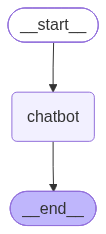

In [42]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))



## 6. Test topic switching and checkpoint persistence

This standalone check uses a temporary UUID thread. It writes a sample question, switches the saved topic, reads the checkpoint using a fresh PostgreSQL connection, verifies the topic and message history, and removes only the test thread rows.



In [43]:
from uuid import uuid4

test_thread_id = str(uuid4())
test_config = {"configurable": {"thread_id": test_thread_id}}
test_question = "Test question for the Astronomy club."

try:
    # Seed a test conversation, then switch its topic without changing its messages.
    graph.update_state(
        test_config,
        {
            "messages": [HumanMessage(content=test_question)],
            "topic": "Astronomy",
        },
    )
    graph.update_state(test_config, {"topic": "Cooking"})

    # Open a second database connection to verify the checkpoint persisted.
    with psycopg.connect(
        SUPABASE_DB_URL,
        autocommit=True,
        row_factory=dict_row,
        prepare_threshold=0,
    ) as verify_conn:
        verify_graph = builder.compile(checkpointer=PostgresSaver(verify_conn))
        persisted = verify_graph.get_state(test_config)

    persisted_messages = persisted.values["messages"]
    assert persisted.values["topic"] == "Cooking"
    assert any(
        isinstance(message, HumanMessage) and message.content == test_question
        for message in persisted_messages
    )
    print("PASS: topic switch and PostgreSQL checkpoint persistence verified.")
finally:
    # Remove only rows belonging to this temporary test thread.
    conn.execute("DELETE FROM checkpoint_writes WHERE thread_id = %s", (test_thread_id,))
    conn.execute("DELETE FROM checkpoint_blobs WHERE thread_id = %s", (test_thread_id,))
    conn.execute("DELETE FROM checkpoints WHERE thread_id = %s", (test_thread_id,))



PASS: topic switch and PostgreSQL checkpoint persistence verified.


## 7. Add PostgreSQL thread and display helpers

The thread list is read from the LangGraph checkpoints table. For each thread, the saved state supplies its topic and the first user question preview.



In [44]:
def new_thread_id() -> str:
    """Return a new UUID string for a conversation."""
    return str(uuid4())

def thread_config(thread_id: str) -> dict:
    return {"configurable": {"thread_id": thread_id}}

def message_text(message) -> str:
    """Convert a message body to readable text for the UI."""
    content = getattr(message, "content", "")
    if isinstance(content, str):
        return content
    if isinstance(content, list):
        parts = []
        for item in content:
            if isinstance(item, dict):
                parts.append(str(item.get("text", "")))
            else:
                parts.append(str(item))
        return " ".join(part for part in parts if part).strip()
    return str(content)

def history_for_ui(messages: list) -> list[dict]:
    """Convert LangChain messages to Gradio's messages format."""
    history = []
    for message in messages:
        if isinstance(message, HumanMessage):
            role = "user"
        elif isinstance(message, AIMessage):
            role = "assistant"
        else:
            # System prompts are deliberately not part of the displayed chat.
            continue

        text = message_text(message)
        if text:
            history.append({"role": role, "content": text})
    return history

def fetch_saved_threads() -> list[tuple[str, str]]:
    """Read every root thread from PostgreSQL and return (label, thread_id)."""
    rows = conn.execute(
        """
        SELECT thread_id, MAX(checkpoint_id) AS latest_checkpoint_id
        FROM checkpoints
        WHERE checkpoint_ns = ''
        GROUP BY thread_id
        ORDER BY latest_checkpoint_id DESC
        """
    ).fetchall()

    choices = []
    for row in rows:
        thread_id = row["thread_id"]
        snapshot = graph.get_state(thread_config(thread_id))
        values = snapshot.values or {}
        topic = values.get("topic", DEFAULT_TOPIC)
        messages = values.get("messages", [])

        first_question = next(
            (
                message_text(message).replace("\n", " ").strip()
                for message in messages
                if isinstance(message, HumanMessage)
            ),
            "No question yet",
        )
        preview = first_question if len(first_question) <= 40 else first_question[:37] + "..."
        label = f"{topic} | {preview}"
        choices.append((label, thread_id))

    return choices

def load_saved_thread(thread_id: str):
    """Restore a thread's active topic and conversation history into the UI."""
    if not thread_id:
        return None, DEFAULT_TOPIC, []

    snapshot = graph.get_state(thread_config(thread_id))
    values = snapshot.values or {}
    return (
        thread_id,
        values.get("topic", DEFAULT_TOPIC),
        history_for_ui(values.get("messages", [])),
    )



## 8. Build the Gradio Blocks interface

The interface includes a club selector, saved conversations, a new conversation button, a chat window, and a message box with a visible Send button. Clicking Send or pressing Enter submits the message. Changing clubs immediately updates the active thread checkpoint.




In [45]:
import gradio as gr

def update_dropdown(choices: list[tuple[str, str]], selected: str | None):
    """Return a Gradio 6 compatible dropdown configuration update."""
    return gr.Dropdown(
        choices=choices,
        value=selected,
        label="Saved Conversations",
    )

def start_new_conversation(topic: str):
    """Create a fresh checkpointed thread and clear the visible chat."""
    topic = topic if topic in CLUBS else DEFAULT_TOPIC
    thread_id = new_thread_id()

    # Seed the new thread without calling the model.
    graph.update_state(
        thread_config(thread_id),
        {"messages": [], "topic": topic},
    )

    choices = fetch_saved_threads()
    return thread_id, [], update_dropdown(choices, thread_id)

def change_active_topic(topic: str, thread_id: str):
    """Persist a club change immediately and keep the existing message history."""
    topic = topic if topic in CLUBS else DEFAULT_TOPIC

    if not thread_id:
        thread_id = new_thread_id()
        graph.update_state(
            thread_config(thread_id),
            {"messages": [], "topic": topic},
        )
        history = []
    else:
        config = thread_config(thread_id)
        graph.update_state(config, {"topic": topic})
        snapshot = graph.get_state(config)
        history = history_for_ui((snapshot.values or {}).get("messages", []))

    choices = fetch_saved_threads()
    return history, update_dropdown(choices, thread_id)

def select_saved_conversation(thread_id: str):
    return load_saved_thread(thread_id)

def send_message(message: str, thread_id: str, topic: str):
    """Invoke the graph for a user message and refresh the saved thread menu."""
    message = (message or "").strip()
    if not message:
        current = graph.get_state(thread_config(thread_id)) if thread_id else None
        history = history_for_ui((current.values or {}).get("messages", [])) if current else []
        return "", history, thread_id, update_dropdown(fetch_saved_threads(), thread_id)

    topic = topic if topic in CLUBS else DEFAULT_TOPIC
    if not thread_id:
        thread_id = new_thread_id()
        graph.update_state(
            thread_config(thread_id),
            {"messages": [], "topic": topic},
        )

    result = graph.invoke(
        {"messages": [HumanMessage(content=message)]},
        config=thread_config(thread_id),
    )
    history = history_for_ui(result.get("messages", []))
    choices = fetch_saved_threads()
    return "", history, thread_id, update_dropdown(choices, thread_id)

with gr.Blocks(title="Club Chatbot") as demo:
    gr.Markdown(
        "# Club Chatbot\n"
        "Choose a club and keep a separate, saved conversation for each thread."
    )

    active_thread = gr.State(value=None)

    with gr.Row():
        topic_dropdown = gr.Dropdown(
            choices=CLUBS,
            value=DEFAULT_TOPIC,
            label="Active Club",
            interactive=True,
        )
        saved_dropdown = gr.Dropdown(
            choices=fetch_saved_threads(),
            value=None,
            label="Saved Conversations",
            interactive=True,
        )
        new_button = gr.Button("New Conversation")

    chat_window = gr.Chatbot(type="messages", label="Conversation", height=440)
    with gr.Row():
        message_box = gr.Textbox(
            label="Your message",
            placeholder="Ask a question about the active club...",
            lines=2,
            scale=8,
        )
        send_button = gr.Button("Send", variant="primary")

    # Create a fresh conversation when a browser session opens.
    demo.load(
        start_new_conversation,
        inputs=topic_dropdown,
        outputs=[active_thread, chat_window, saved_dropdown],
    )

    # The input event fires for a user selection, not a programmatic dropdown update.
    saved_dropdown.input(
        select_saved_conversation,
        inputs=saved_dropdown,
        outputs=[active_thread, topic_dropdown, chat_window],
    )

    # Persist topic changes immediately while preserving the chat transcript.
    topic_dropdown.input(
        change_active_topic,
        inputs=[topic_dropdown, active_thread],
        outputs=[chat_window, saved_dropdown],
    )

    new_button.click(
        start_new_conversation,
        inputs=topic_dropdown,
        outputs=[active_thread, chat_window, saved_dropdown],
    )

    message_box.submit(
        send_message,
        inputs=[message_box, active_thread, topic_dropdown],
        outputs=[message_box, chat_window, active_thread, saved_dropdown],
    )
    send_button.click(
        send_message,
        inputs=[message_box, active_thread, topic_dropdown],
        outputs=[message_box, chat_window, active_thread, saved_dropdown],
    )




/tmp/ipykernel_4826/498558033.py:95: DeprecationWarning: The default value of 'allow_tags' in gr.Chatbot will be changed from False to True in Gradio 6.0. You will need to explicitly set allow_tags=False if you want to disable tags in your chatbot.
  chat_window = gr.Chatbot(type="messages", label="Conversation", height=440)


## 9. Launch the app

The public share link lets anyone who has it reach this running Gradio session without an extra login. Link holders can use your API quota and interact with conversation data in Supabase, so share it only with trusted people. Keep your Colab runtime open while you use the app. Stop the cell to shut down the app.



In [46]:
demo.queue()
demo.launch(share=True)



Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7ff171ad51b30e047c.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
